In [1]:
##import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline 

Text(0, 0.5, 'Y dataset')

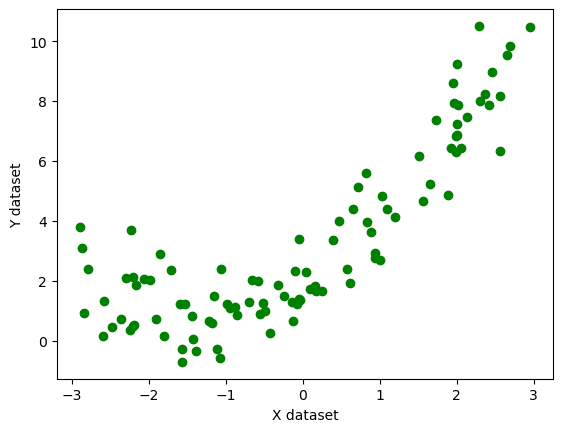

In [2]:
## creating a random dataset 
X = 6 * np.random.rand(100, 1) - 3
y =0.5 * X**2 + 1.5*X + 2 + np.random.randn(100, 1)
# quadratic equation used- y=0.5x^2+1.5x+2+outliers
plt.scatter(X,y,color='g')
plt.xlabel('X dataset')
plt.ylabel('Y dataset')

In [6]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [7]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [8]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [10]:
from sklearn.metrics import r2_score
score=r2_score(y_test,lr.predict(X_test))
print(score)

0.693014826378037


Text(0, 0.5, 'Y')

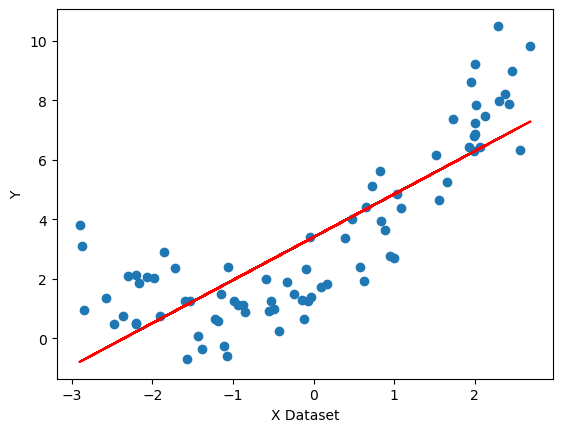

In [11]:
## visualize this model
plt.plot(X_train,lr.predict(X_train),color='r')
plt.scatter(X_train,y_train)
plt.xlabel("X Dataset")
plt.ylabel("Y")

## Apply polynomial transformation

In [12]:
from sklearn.preprocessing import PolynomialFeatures

In [13]:
poly=PolynomialFeatures(degree=2,include_bias=True)

In [14]:
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [15]:
X_train_poly

array([[ 1.00000000e+00,  1.99396168e+00,  3.97588319e+00],
       [ 1.00000000e+00,  2.00041689e+00,  4.00166774e+00],
       [ 1.00000000e+00, -2.84364663e+00,  8.08632618e+00],
       [ 1.00000000e+00,  8.83900600e-01,  7.81280271e-01],
       [ 1.00000000e+00, -2.90198572e+00,  8.42152112e+00],
       [ 1.00000000e+00, -1.38933182e+00,  1.93024291e+00],
       [ 1.00000000e+00,  9.44396534e-01,  8.91884813e-01],
       [ 1.00000000e+00, -2.16449488e+00,  4.68503808e+00],
       [ 1.00000000e+00,  8.20391504e-01,  6.73042219e-01],
       [ 1.00000000e+00, -4.89963233e-01,  2.40063969e-01],
       [ 1.00000000e+00, -2.57841502e+00,  6.64822401e+00],
       [ 1.00000000e+00, -1.90281830e+00,  3.62071749e+00],
       [ 1.00000000e+00,  1.73459929e+00,  3.00883471e+00],
       [ 1.00000000e+00, -4.24643840e-01,  1.80322391e-01],
       [ 1.00000000e+00, -1.11274392e+00,  1.23819904e+00],
       [ 1.00000000e+00, -9.50057202e-02,  9.02608688e-03],
       [ 1.00000000e+00, -3.39876471e-02

In [20]:

from sklearn.metrics import r2_score
lr = LinearRegression()
lr.fit(X_train_poly, y_train)
y_pred = lr.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.8985265858810139


### the score increased 

In [22]:
print(lr.coef_)

[[0.         1.48847588 0.53902872]]


In [23]:
print(lr.intercept_)

[1.98328292]


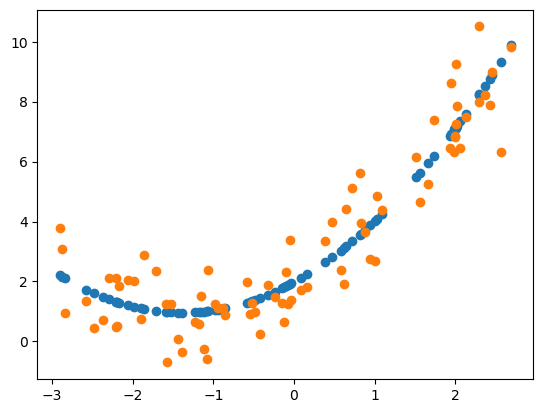

In [24]:
plt.scatter(X_train,lr.predict(X_train_poly))
plt.scatter(X_train,y_train)

## trying to increase degrees

In [25]:
poly=PolynomialFeatures(degree=3,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [26]:

from sklearn.metrics import r2_score
lr = LinearRegression()
lr.fit(X_train_poly, y_train)
y_pred = lr.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.8960866914016791


In [27]:
#3 Prediction of new data set
X_new = np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00,
        -2.70000000e+01],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00,
        -2.61940839e+01],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00,
        -2.54043665e+01],
       [ 1.00000000e+00, -2.90954774e+00,  8.46546804e+00,
        -2.46306834e+01],
       [ 1.00000000e+00, -2.87939698e+00,  8.29092700e+00,
        -2.38728702e+01],
       [ 1.00000000e+00, -2.84924623e+00,  8.11820409e+00,
        -2.31307624e+01],
       [ 1.00000000e+00, -2.81909548e+00,  7.94729931e+00,
        -2.24041955e+01],
       [ 1.00000000e+00, -2.78894472e+00,  7.77821267e+00,
        -2.16930052e+01],
       [ 1.00000000e+00, -2.75879397e+00,  7.61094417e+00,
        -2.09970269e+01],
       [ 1.00000000e+00, -2.72864322e+00,  7.44549380e+00,
        -2.03160961e+01],
       [ 1.00000000e+00, -2.69849246e+00,  7.28186157e+00,
        -1.96500486e+01],
       [ 1.00000000e+00, -2.66834171e+00,  7.12004747e+00,
      

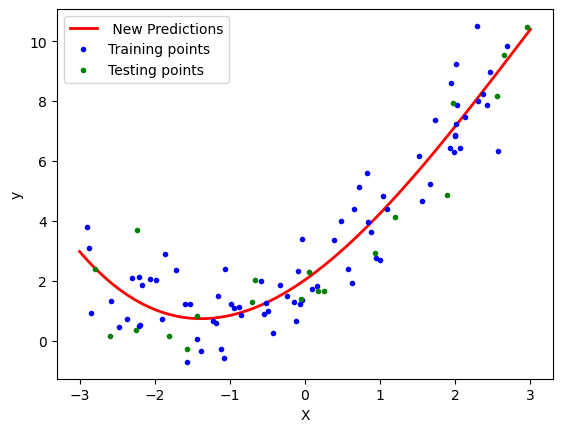

In [28]:
y_new = lr.predict(X_new_poly)
plt.plot(X_new, y_new, "r-", linewidth=2, label=" New Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()